In [21]:
# STEP 1: IMPORT LIBRARIES AND LOAD DATA

# Pandas for working with datasets
import pandas as pd

# NumPy for numerical operations
import numpy as np

# Matplotlib for visualizations
import matplotlib.pyplot as plt

# Linear Regression model
from sklearn.linear_model import LinearRegression

# Metrics to evaluate our predictions
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the cleaned dataset
laliga = pd.read_csv("../LinearRegression/laliga_cleaned.csv")

# Sort teams chronologically
laliga = laliga.sort_values(
    by=["squad", "season"]
).reset_index(drop=True)

# Display the dataset
print("Dataset shape:", laliga.shape)
display(laliga.head())

Dataset shape: (240, 20)


,rk,squad,mp,w,d,l,gf,ga,gd,pts,pts/mp,attendance,top_team_scorer,goalkeeper,notes,season,xg,xga,xgd,xgd/90
0,9,Alavés,38,14,13,11,41,43,-2,55,1.45,18143.0,Deyverson - 7,Fernando Pacheco,NaN,2016,NaN,NaN,NaN,NaN
1,14,Alavés,38,15,2,21,40,50,-10,47,1.24,18845.0,Munir El Haddadi - 10,Fernando Pacheco,NaN,2017,38.5,55.9,-17.4,-0.46
2,11,Alavés,38,13,11,14,39,50,-11,50,1.32,17295.0,Jonathan Calleri - 9,Fernando Pacheco,NaN,2018,41.1,53.2,-12.1,-0.32
3,16,Alavés,38,10,9,19,34,59,-25,39,1.03,12177.0,"Joselu, Lucas Pérez - 11",Fernando Pacheco,NaN,2019,39.3,57.8,-18.5,-0.49
4,16,Alavés,38,9,11,18,36,57,-21,38,1.00,NaN,Joselu - 11,Fernando Pacheco,NaN,2020,42.6,49.9,-7.3,-0.19


In [22]:
# STEP 2: CREATE NEXT-SEASON POINTS TARGETS

# Sort the dataset by team and season
# This ensures each team's seasons are in chronological order
laliga = laliga.sort_values(
    by=["squad", "season"]
).copy()

# For each team, get the points from its next recorded season
laliga["next_season_pts"] = (
    laliga.groupby("squad")["pts"].shift(-1)
)

# Also get the year of that next recorded season
laliga["next_season"] = (
    laliga.groupby("squad")["season"].shift(-1)
)

# Keep only rows where the next season is exactly one year later
# This prevents incorrectly linking seasons across relegation gaps
training_data = laliga[
    laliga["next_season"] == laliga["season"] + 1
].copy()

# Display our new training dataset
print("Training dataset shape:", training_data.shape)

display(
    training_data[
        ["squad", "season", "pts", "next_season", "next_season_pts"]
    ].head(15)
)

Training dataset shape: (187, 22)


,squad,season,pts,next_season,next_season_pts
0,Alavés,2016,55,2017.0,47.0
1,Alavés,2017,47,2018.0,50.0
2,Alavés,2018,50,2019.0,39.0
3,Alavés,2019,39,2020.0,38.0
4,Alavés,2020,38,2021.0,31.0
6,Alavés,2023,46,2024.0,42.0
7,Alavés,2024,42,2025.0,43.0
10,Almería,2022,41,2023.0,21.0
12,Athletic Club,2014,55,2015.0,62.0
13,Athletic Club,2015,62,2016.0,63.0


In [23]:
# STEP 3: SELECT FEATURES AND TARGET VARIABLE

# Select the previous-season statistics used as inputs
features = ["pts", "w", "gf", "ga", "gd"]

# X contains the input features for our model
X = training_data[features]

# y contains the points earned in the following season
y = training_data["next_season_pts"]

# Display the dimensions
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

# Display the first five feature rows
print("\nInput features:")
display(X.head())

# Display the first five target values
print("\nTarget values:")
display(y.head())

Features (X) shape: (187, 5)
Target (y) shape: (187,)

Input features:


,pts,w,gf,ga,gd
0,55,14,41,43,-2
1,47,15,40,50,-10
2,50,13,39,50,-11
3,39,10,34,59,-25
4,38,9,36,57,-21



Target values:


0    47.0
1    50.0
2    39.0
3    38.0
4    31.0
Name: next_season_pts, dtype: float64

In [24]:
# STEP 4: SPLIT DATA INTO TRAINING AND TESTING SETS

# Training examples: target seasons up to 2022/23
train_data = training_data[
    training_data["next_season"] <= 2022
].copy()

# Testing examples: target seasons from 2023/24 onward
test_data = training_data[
    training_data["next_season"] >= 2023
].copy()

# Select the same five features for both datasets
X_train = train_data[features]
X_test = test_data[features]

# Select next-season final points as our target
y_train = train_data["next_season_pts"]
y_test = test_data["next_season_pts"]

# Display dataset dimensions
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Verify the chronological split
print("\nTraining target seasons:",
      sorted(train_data["next_season"].unique()))

print("\nTesting target seasons:",
      sorted(test_data["next_season"].unique()))

X_train shape: (136, 5)
X_test shape: (51, 5)
y_train shape: (136,)
y_test shape: (51,)

Training target seasons: [np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0)]

Testing target seasons: [np.float64(2023.0), np.float64(2024.0), np.float64(2025.0)]


In [25]:
# STEP 5: TRAIN OUR LINEAR REGRESSION MODEL

# Create a Linear Regression model
model = LinearRegression()

# Train the model using historical data
# X_train contains previous-season statistics
# y_train contains the following season's final points
model.fit(X_train, y_train)

# Generate predictions for our testing dataset
# The model has never been trained on these target seasons
y_pred = model.predict(X_test)

# Display the first 10 predictions
print("First 10 predictions:\n")

for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(
        f"Actual: {actual:.0f} points | "
        f"Predicted: {predicted:.2f} points"
    )

First 10 predictions:

Actual: 42 points | Predicted: 46.39 points
Actual: 43 points | Predicted: 43.88 points
Actual: 21 points | Predicted: 40.71 points
Actual: 68 points | Predicted: 52.37 points
Actual: 70 points | Predicted: 64.41 points
Actual: 45 points | Predicted: 66.11 points
Actual: 76 points | Predicted: 72.53 points
Actual: 76 points | Predicted: 69.47 points
Actual: 69 points | Predicted: 72.24 points
Actual: 85 points | Predicted: 83.07 points


In [26]:
# STEP 7: EVALUATE OUR LINEAR REGRESSION MODEL

# Calculate Mean Absolute Error (MAE)
# Average absolute difference between predicted and actual points
mae = mean_absolute_error(y_test, y_pred)

# Calculate Mean Squared Error (MSE)
# Squares the errors, giving larger mistakes more weight
mse = mean_squared_error(y_test, y_pred)

# Calculate Root Mean Squared Error (RMSE)
# Converts MSE back into points
rmse = np.sqrt(mse)

# Calculate R-squared (R²)
# Measures performance relative to predicting the test-set mean
r2 = r2_score(y_test, y_pred)

# Display evaluation results
print("LINEAR REGRESSION MODEL PERFORMANCE")
print("-----------------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f} points")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} points")
print(f"R² Score: {r2:.3f}")

LINEAR REGRESSION MODEL PERFORMANCE
-----------------------------------
Mean Absolute Error (MAE): 7.89 points
Root Mean Squared Error (RMSE): 10.83 points
R² Score: 0.605


In [27]:
# STEP 8: COMPARE LINEAR REGRESSION WITH A BASELINE

# Our baseline predicts that each team will earn
# the same number of points as the previous season
baseline_pred = test_data["pts"]

# Calculate baseline evaluation metrics
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

# Compare our Linear Regression model against the baseline
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Previous Season Baseline"],
    "MAE": [mae, baseline_mae],
    "RMSE": [rmse, baseline_rmse],
    "R²": [r2, baseline_r2]
})

# Round results to 3 decimal places
display(comparison.round(3))

,Model,MAE,RMSE,R²
0,Linear Regression,7.890,10.830,0.605
1,Previous Season Baseline,7.843,11.324,0.568


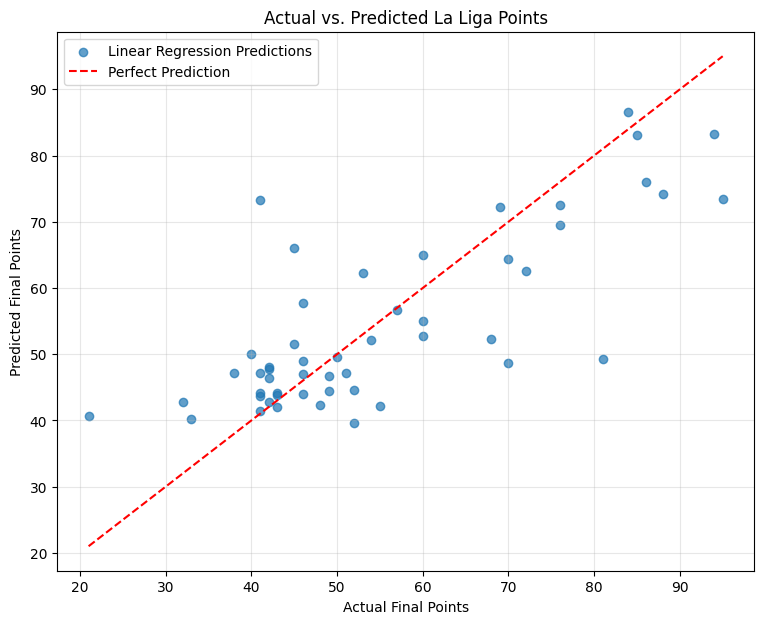

In [28]:
# STEP 9: VISUALIZE ACTUAL VS. PREDICTED POINTS

# Create a figure
plt.figure(figsize=(9, 7))

# Plot actual points against predicted points
# Each dot represents one team-season in our test set
plt.scatter(
    y_test,
    y_pred,
    alpha=0.7,
    label="Linear Regression Predictions"
)

# Draw a reference line representing perfect predictions
# A point on this line has predicted points = actual points
min_pts = min(y_test.min(), y_pred.min())
max_pts = max(y_test.max(), y_pred.max())

plt.plot(
    [min_pts, max_pts],
    [min_pts, max_pts],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

# Add titles and labels
plt.title("Actual vs. Predicted La Liga Points")
plt.xlabel("Actual Final Points")
plt.ylabel("Predicted Final Points")

# Add legend and grid
plt.legend()
plt.grid(alpha=0.3)

# Display the graph
plt.show()

In [29]:
# STEP 10: ANALYZE OUR LARGEST PREDICTION ERRORS

# Create a DataFrame containing the testing results
results = test_data[
    ["squad", "season", "next_season", "pts", "next_season_pts"]
].copy()

# Add the model's predicted points
results["predicted_pts"] = y_pred

# Calculate prediction error
# Positive = model overestimated
# Negative = model underestimated
results["error"] = (
    results["predicted_pts"] - results["next_season_pts"]
)

# Calculate absolute error
results["absolute_error"] = results["error"].abs()

# Rename columns to make the table easier to understand
results = results.rename(columns={
    "pts": "previous_season_pts",
    "next_season_pts": "actual_pts"
})

# Sort by absolute error, largest first
results = results.sort_values(
    by="absolute_error",
    ascending=False
)

# Display the 10 largest prediction errors
display(results.head(10).round(2))

,squad,season,next_season,previous_season_pts,actual_pts,predicted_pts,error,absolute_error
112,Girona,2023,2024.0,81,41.0,73.33,32.33,32.33
111,Girona,2022,2023.0,49,81.0,49.30,-31.70,31.70
181,Real Madrid,2022,2023.0,78,95.0,73.51,-21.49,21.49
237,Villarreal,2023,2024.0,53,70.0,48.60,-21.40,21.40
22,Athletic Club,2024,2025.0,70,45.0,66.11,21.11,21.11
10,Almería,2022,2023.0,41,21.0,40.71,19.71,19.71
20,Athletic Club,2022,2023.0,51,68.0,52.37,-15.63,15.63
45,Barcelona,2023,2024.0,85,88.0,74.15,-13.85,13.85
68,Celta Vigo,2023,2024.0,41,55.0,42.19,-12.81,12.81
170,Rayo Vallecano,2023,2024.0,38,52.0,39.62,-12.38,12.38


In [30]:
# STEP 11: CREATE HISTORICAL PERFORMANCE FEATURES

# Sort teams chronologically
laliga = laliga.sort_values(
    by=["squad", "season"]
).copy()

# Calculate a rolling average of points
# Uses up to 3 recorded seasons, including the current input season
laliga["avg_pts_last_3"] = (
    laliga.groupby("squad")["pts"]
    .transform(
        lambda points: points.rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)

# Display an example using Girona
display(
    laliga[laliga["squad"] == "Girona"][
        ["season", "pts", "avg_pts_last_3"]
    ]
)

,season,pts,avg_pts_last_3
109,2017,51,51.000000
110,2018,37,44.000000
111,2022,49,45.666667
112,2023,81,55.666667
113,2024,41,57.000000
114,2025,41,54.333333


In [31]:
# STEP 12: PREPARE FEATURES FOR MODEL COMPARISON

# Rebuild our training dataset so it includes
# the rolling average we just calculated
training_data = laliga[
    laliga["next_season"] == laliga["season"] + 1
].copy()

# Our original five features
original_features = [
    "pts",
    "w",
    "gf",
    "ga",
    "gd"
]

# Our new feature set includes historical average points
improved_features = [
    "pts",
    "w",
    "gf",
    "ga",
    "gd",
    "avg_pts_last_3"
]

# Use earlier seasons for model training
# Target seasons: 2015/16 through 2020/21
validation_train = training_data[
    training_data["next_season"] <= 2020
].copy()

# Use later seasons for validation
# Target seasons: 2021/22 and 2022/23
validation_test = training_data[
    training_data["next_season"].between(2021, 2022)
].copy()

# Display dataset sizes
print("Training examples:", len(validation_train))
print("Validation examples:", len(validation_test))

# Verify which target seasons are used
print("\nTraining seasons:",
      sorted(validation_train["next_season"].unique()))

print("\nValidation seasons:",
      sorted(validation_test["next_season"].unique()))

Training examples: 102
Validation examples: 34

Training seasons: [np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0), np.float64(2020.0)]

Validation seasons: [np.float64(2021.0), np.float64(2022.0)]


In [32]:
# STEP 13: COMPARE ORIGINAL VS. IMPROVED MODEL

# MODEL 1: ORIGINAL FIVE FEATURES

# Create the first Linear Regression model
model_original = LinearRegression()

# Train using our original five features
model_original.fit(
    validation_train[original_features],
    validation_train["next_season_pts"]
)

# Predict points for the validation seasons
pred_original = model_original.predict(
    validation_test[original_features]
)


# MODEL 2: ADD HISTORICAL AVERAGE POINTS

# Create a second Linear Regression model
model_improved = LinearRegression()

# Train using six features, including our rolling average
model_improved.fit(
    validation_train[improved_features],
    validation_train["next_season_pts"]
)

# Predict points for the same validation seasons
pred_improved = model_improved.predict(
    validation_test[improved_features]
)


# --------------------------------------------------
# COMPARE MODEL PERFORMANCE
# --------------------------------------------------

# Actual final points for our validation seasons
y_validation = validation_test["next_season_pts"]

# Create a comparison table
comparison = pd.DataFrame({
    "Model": [
        "Original Linear Regression",
        "Linear Regression + Rolling Average"
    ],

    "MAE": [
        mean_absolute_error(y_validation, pred_original),
        mean_absolute_error(y_validation, pred_improved)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_validation, pred_original)),
        np.sqrt(mean_squared_error(y_validation, pred_improved))
    ],

    "R²": [
        r2_score(y_validation, pred_original),
        r2_score(y_validation, pred_improved)
    ]
})

# Display the results
display(comparison.round(3))

,Model,MAE,RMSE,R²
0,Original Linear Regression,6.283,8.277,0.725
1,Linear Regression + Rolling Average,6.599,8.362,0.719


In [33]:
# STEP 14: TRAIN FINAL LINEAR REGRESSION MODEL

# Use the original five features selected during validation
final_features = ["pts", "w", "gf", "ga", "gd"]

# Create a new Linear Regression model
final_model = LinearRegression()

# Train using all 186 historical examples
final_model.fit(
    training_data[final_features],
    training_data["next_season_pts"]
)

# Confirm that training completed
print("Final model trained successfully!")
print("Training examples:", len(training_data))

# Display the model's intercept
print("\nIntercept:", round(final_model.intercept_, 3))

# Display the coefficient associated with each feature
coefficients = pd.DataFrame({
    "Feature": final_features,
    "Coefficient": final_model.coef_
})

display(coefficients.round(3))

Final model trained successfully!
Training examples: 187

Intercept: 34.482


,Feature,Coefficient
0,pts,0.226
1,w,0.484
2,gf,0.085
3,ga,-0.128
4,gd,0.212


In [34]:
# STEP 15: PREDICT 2026/27 FINAL LA LIGA POINTS

# Select all teams from the 2025/26 season
laliga_2025 = laliga[
    laliga["season"] == 2025
].copy()

# Select the five features used to train our model
X_2026 = laliga_2025[final_features]

# Predict final points for the following season (2026/27)
laliga_2025["predicted_pts_2026"] = final_model.predict(X_2026)

# Round predictions to one decimal place
laliga_2025["predicted_pts_2026"] = (
    laliga_2025["predicted_pts_2026"].round(1)
)

# Sort teams by predicted points (highest first)
predictions_2026 = laliga_2025[
    ["squad", "pts", "predicted_pts_2026"]
].sort_values(
    by="predicted_pts_2026",
    ascending=False
)

# Rename columns for readability
predictions_2026 = predictions_2026.rename(columns={
    "pts": "points_2025_26",
    "predicted_pts_2026": "predicted_points_2026_27"
})

# Display predictions
display(predictions_2026)

,squad,points_2025_26,predicted_points_2026_27
47,Barcelona,94,86.7
184,Real Madrid,86,78.0
239,Villarreal,72,67.2
35,Atlético Madrid,69,63.7
58,Betis,60,56.5
70,Celta Vigo,54,52.9
108,Getafe,51,49.9
172,Rayo Vallecano,50,48.8
196,Real Sociedad,46,47.0
222,Valencia,49,46.8


In [35]:
# STEP 16: REMOVE RELEGATED TEAMS FROM PREDICTIONS

# Identify teams marked as relegated in 2025/26
relegated = laliga_2025[
    laliga_2025["notes"]
    .fillna("")
    .str.contains("Relegated", case=False)
]

# Display the relegated clubs
print("Relegated teams:")
display(relegated[["squad", "pts", "notes"]])

# Keep only teams that were not relegated
returning_teams = laliga_2025[
    ~laliga_2025.index.isin(relegated.index)
].copy()

# Sort by predicted 2026/27 points
returning_teams = returning_teams.sort_values(
    by="predicted_pts_2026",
    ascending=False
)

# Display returning teams
print("\nReturning teams:", len(returning_teams))

display(
    returning_teams[
        ["squad", "pts", "predicted_pts_2026"]
    ]
)

Relegated teams:


,squad,pts,notes
114,Girona,41,Relegated
151,Mallorca,42,Relegated
164,Oviedo,29,Relegated



Returning teams: 17


,squad,pts,predicted_pts_2026
47,Barcelona,94,86.7
184,Real Madrid,86,78.0
239,Villarreal,72,67.2
35,Atlético Madrid,69,63.7
58,Betis,60,56.5
70,Celta Vigo,54,52.9
108,Getafe,51,49.9
172,Rayo Vallecano,50,48.8
196,Real Sociedad,46,47.0
222,Valencia,49,46.8


In [36]:
# STEP 17: IDENTIFY HISTORICAL PROMOTED TEAMS

# Create a copy of our historical La Liga dataset
promotion_data = laliga.copy()

# For each team, identify whether it appeared
# in La Liga during the previous season
promotion_data["played_previous_season"] = (
    promotion_data.apply(
        lambda row: (
            (laliga["squad"] == row["squad"]) &
            (laliga["season"] == row["season"] - 1)
        ).any(),
        axis=1
    )
)

# Identify teams that did not play in La Liga
# during the previous season
promoted_teams = promotion_data[
    (promotion_data["played_previous_season"] == False) &
    (promotion_data["season"] > 2014)
].copy()

# Display promoted teams and their final points
display(
    promoted_teams[
        ["season", "squad", "rk", "pts"]
    ].sort_values(
        by=["season", "rk"]
    )
)

# Calculate summary statistics
print("Number of promoted team-seasons:", len(promoted_teams))
print("Average points:", round(promoted_teams["pts"].mean(), 2))
print("Median points:", promoted_teams["pts"].median())
print("Minimum points:", promoted_teams["pts"].min())
print("Maximum points:", promoted_teams["pts"].max())

,season,squad,rk,pts
48,2015,Betis,10,45
128,2015,Las Palmas,11,44
209,2015,Sporting Gijón,17,39
0,2016,Alavés,9,55
133,2016,Leganés,17,35
156,2016,Osasuna,19,22
100,2017,Getafe,8,55
109,2017,Girona,10,51
140,2017,Levante,15,46
223,2018,Valladolid,16,41


Number of promoted team-seasons: 33
Average points: 40.15
Median points: 41.0
Minimum points: 16
Maximum points: 56


In [37]:
# STEP 18: BACKTEST PROMOTED-TEAM POINTS PREDICTIONS

# Sort promoted teams by season
promoted_teams = promoted_teams.sort_values(
    by=["season", "squad"]
).copy()

# Store predictions and actual results
promotion_predictions = []

# Start testing from 2018/19
# This gives us three earlier seasons of historical data
for season in sorted(promoted_teams["season"].unique()):

    if season < 2018:
        continue

    # Historical promoted teams from BEFORE the target season
    historical = promoted_teams[
        promoted_teams["season"] < season
    ]

    # Teams promoted in the season we're predicting
    current = promoted_teams[
        promoted_teams["season"] == season
    ]

    # Predict using the historical average
    predicted_points = historical["pts"].mean()

    # Store the results for each promoted team
    for _, team in current.iterrows():

        promotion_predictions.append({
            "season": season,
            "squad": team["squad"],
            "actual_pts": team["pts"],
            "predicted_pts": predicted_points
        })

# Convert results into a DataFrame
promotion_results = pd.DataFrame(promotion_predictions)

# Calculate prediction errors
promotion_results["absolute_error"] = (
    promotion_results["actual_pts"] -
    promotion_results["predicted_pts"]
).abs()

# Display model performance
print("PROMOTED-TEAM BASELINE PERFORMANCE")
print("----------------------------------")

print(
    "MAE:",
    round(
        mean_absolute_error(
            promotion_results["actual_pts"],
            promotion_results["predicted_pts"]
        ),
        2
    )
)

print(
    "RMSE:",
    round(
        np.sqrt(
            mean_squared_error(
                promotion_results["actual_pts"],
                promotion_results["predicted_pts"]
            )
        ),
        2
    )
)

# Display the predictions
display(promotion_results.round(2))

PROMOTED-TEAM BASELINE PERFORMANCE
----------------------------------
MAE: 6.56
RMSE: 9.27


,season,squad,actual_pts,predicted_pts,absolute_error
0,2018,Huesca,33,43.56,10.56
1,2018,Rayo Vallecano,32,43.56,11.56
2,2018,Valladolid,41,43.56,2.56
3,2019,Granada,56,41.50,14.50
4,2019,Mallorca,33,41.50,8.50
5,2019,Osasuna,52,41.50,10.50
6,2020,Cádiz,44,42.60,1.40
7,2020,Elche,36,42.60,6.60
8,2020,Huesca,34,42.60,8.60
9,2021,Espanyol,42,41.83,0.17


In [38]:
# STEP 19: PREPARE PROMOTED-TEAM POINTS BASELINE

# Calculate the average points earned by promoted teams
# across all historical seasons in our dataset
promoted_points_baseline = promoted_teams["pts"].mean()

# Round the prediction to one decimal place
promoted_points_baseline = round(
    promoted_points_baseline, 1
)

# Display the baseline prediction
print("Promoted-team baseline prediction:",
      promoted_points_baseline, "points")

# Display the number of historical examples
print("Historical promoted team-seasons:",
      len(promoted_teams))

Promoted-team baseline prediction: 40.2 points
Historical promoted team-seasons: 33


In [39]:
# STEP 20: CREATE PROMOTED-TEAM PREDICTIONS

# Teams promoted to La Liga for the 2026/27 season
promoted_2026 = [
    "Racing Santander",
    "La Coruña",
    "Málaga"
]

# Create a DataFrame for promoted teams
promoted_predictions = pd.DataFrame({
    "squad": promoted_2026,
    "predicted_pts_2026": promoted_points_baseline
})

# Display predictions
display(promoted_predictions)

,squad,predicted_pts_2026
0,Racing Santander,40.2
1,La Coruña,40.2
2,Málaga,40.2


In [40]:
# STEP 21: GENERATE 2026/27 PREDICTED STANDINGS

# Select the returning teams and their predictions
returning_predictions = returning_teams[
    ["squad", "predicted_pts_2026"]
].copy()

# Label predictions from Linear Regression
returning_predictions["prediction_method"] = "Linear Regression"

# Label predictions for promoted teams
promoted_predictions["prediction_method"] = "Historical Average"

# Combine returning and promoted teams
final_standings = pd.concat(
    [returning_predictions, promoted_predictions],
    ignore_index=True
)

# Sort teams by predicted points (highest first)
final_standings = final_standings.sort_values(
    by="predicted_pts_2026",
    ascending=False
).reset_index(drop=True)

# Assign predicted league positions
final_standings.insert(
    0,
    "predicted_rank",
    range(1, len(final_standings) + 1)
)

# Display the complete table
display(final_standings)

# Verify that we have exactly 20 unique teams
print("Total teams:", len(final_standings))
print("Unique teams:", final_standings["squad"].nunique())

,predicted_rank,squad,predicted_pts_2026,prediction_method
0,1,Barcelona,86.7,Linear Regression
1,2,Real Madrid,78.0,Linear Regression
2,3,Villarreal,67.2,Linear Regression
3,4,Atlético Madrid,63.7,Linear Regression
4,5,Betis,56.5,Linear Regression
5,6,Celta Vigo,52.9,Linear Regression
6,7,Getafe,49.9,Linear Regression
7,8,Rayo Vallecano,48.8,Linear Regression
8,9,Real Sociedad,47.0,Linear Regression
9,10,Valencia,46.8,Linear Regression


Total teams: 20
Unique teams: 20


In [41]:
# STEP 22: ROUND PREDICTED POINTS

import numpy as np

# Round predicted points to the nearest whole number
final_standings["predicted_pts_2026"] = np.floor(
    final_standings["predicted_pts_2026"] + 0.5
).astype(int)

# Display updated standings
display(final_standings)

,predicted_rank,squad,predicted_pts_2026,prediction_method
0,1,Barcelona,87,Linear Regression
1,2,Real Madrid,78,Linear Regression
2,3,Villarreal,67,Linear Regression
3,4,Atlético Madrid,64,Linear Regression
4,5,Betis,57,Linear Regression
5,6,Celta Vigo,53,Linear Regression
6,7,Getafe,50,Linear Regression
7,8,Rayo Vallecano,49,Linear Regression
8,9,Real Sociedad,47,Linear Regression
9,10,Valencia,47,Linear Regression


In [43]:
# STEP 23: EXPORT FINAL PREDICTED STANDINGS

# Save the predicted standings to a CSV file
final_standings.to_csv(
    "../LinearRegression/laliga_2026_2027_predictions.csv",
    index=False
)

# Confirm the file was saved
print("2026/27 La Liga predictions saved successfully!")

# Display the final standings
display(final_standings)

2026/27 La Liga predictions saved successfully!


,predicted_rank,squad,predicted_pts_2026,prediction_method
0,1,Barcelona,87,Linear Regression
1,2,Real Madrid,78,Linear Regression
2,3,Villarreal,67,Linear Regression
3,4,Atlético Madrid,64,Linear Regression
4,5,Betis,57,Linear Regression
5,6,Celta Vigo,53,Linear Regression
6,7,Getafe,50,Linear Regression
7,8,Rayo Vallecano,49,Linear Regression
8,9,Real Sociedad,47,Linear Regression
9,10,Valencia,47,Linear Regression
